# Quantum Circuits with Qiskit

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/gusfring3369/QC/blob/claude/quantum-circuit-qiskit-d4b5xw/quantum_circuits.ipynb)

This notebook builds and simulates quantum circuits with [Qiskit](https://www.qiskit.org/) and the Aer simulator. Everything runs in your browser on Google Colab; you don't need a quantum computer or an IBM account.

**Contents**
1. Setup
2. Superposition: one qubit and the Hadamard gate
3. Entanglement: the Bell state
4. A 3-qubit GHZ state
5. Quantum teleportation
6. Grover's search algorithm (2 qubits)
7. Deutsch–Jozsa algorithm
8. (Optional) Run on real IBM quantum hardware

Run the cells top to bottom with **Runtime → Run all**, or press `Shift+Enter` on each cell.

## 1. Setup
Install Qiskit, the Aer simulator and the drawing dependencies. On Colab this takes about a minute. If Colab asks you to restart the runtime afterwards, do that and continue from the next cell.

In [1]:
%pip install -q qiskit qiskit-aer matplotlib pylatexenc

In [2]:
import numpy as np
import matplotlib.pyplot as plt

import qiskit
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_histogram, plot_bloch_multivector
from qiskit_aer import AerSimulator

sim = AerSimulator()

def run(qc, shots=1024):
    """Simulate a circuit and return its measurement counts."""
    return sim.run(transpile(qc, sim), shots=shots).result().get_counts()

print("Qiskit version:", qiskit.__version__)

Qiskit version: 2.6.0


## 2. Superposition: one qubit and the Hadamard gate

A qubit starts in $|0\rangle$. The Hadamard gate $H$ puts it into an equal superposition:

$$H|0\rangle = \frac{|0\rangle + |1\rangle}{\sqrt{2}}$$

When measured, it gives 0 or 1, each about half the time.

Statevector: Statevector([0.70710678+0.j, 0.70710678+0.j],
            dims=(2,))


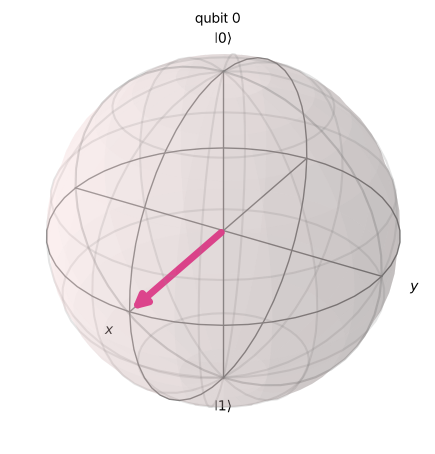

In [3]:
qc = QuantumCircuit(1)
qc.h(0)

# The state before measurement, shown on the Bloch sphere
state = Statevector(qc)
print("Statevector:", state)
plot_bloch_multivector(state)

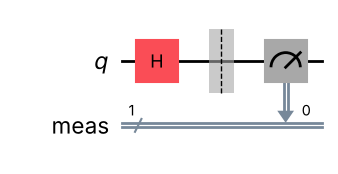

{'1': 490, '0': 534}


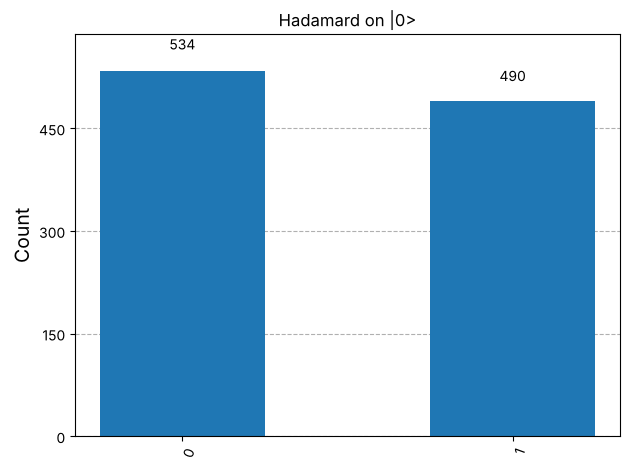

In [4]:
qc.measure_all()
display(qc.draw("mpl"))

counts = run(qc)
print(counts)
plot_histogram(counts, title="Hadamard on |0>")

## 3. Entanglement: the Bell state

A Hadamard followed by a CNOT gives the Bell state

$$|\Phi^+\rangle = \frac{|00\rangle + |11\rangle}{\sqrt{2}}$$

The two qubits are entangled: you only ever measure `00` or `11`, never `01` or `10`.

[0.70710678+0.j,0.        +0.j,0.        +0.j,0.70710678+0.j]


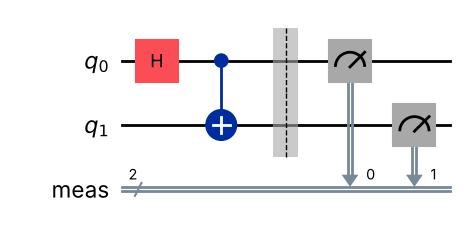

{'00': 507, '11': 517}


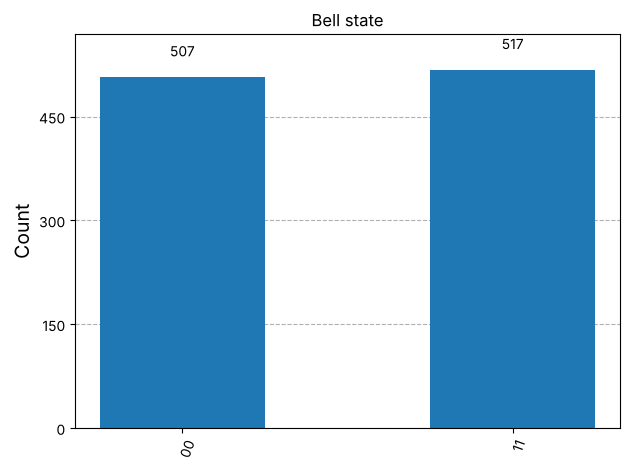

In [5]:
bell = QuantumCircuit(2)
bell.h(0)
bell.cx(0, 1)

print(Statevector(bell).draw("text"))

bell.measure_all()
display(bell.draw("mpl"))

counts = run(bell)
print(counts)
plot_histogram(counts, title="Bell state")

## 4. A 3-qubit GHZ state

The GHZ state extends the Bell state to more qubits: $\frac{|000\rangle + |111\rangle}{\sqrt{2}}$. Change `n` to entangle more qubits.

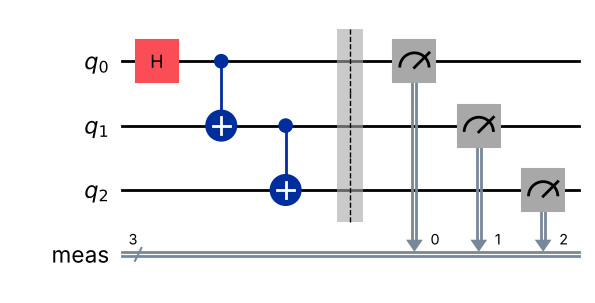

{'111': 487, '000': 537}


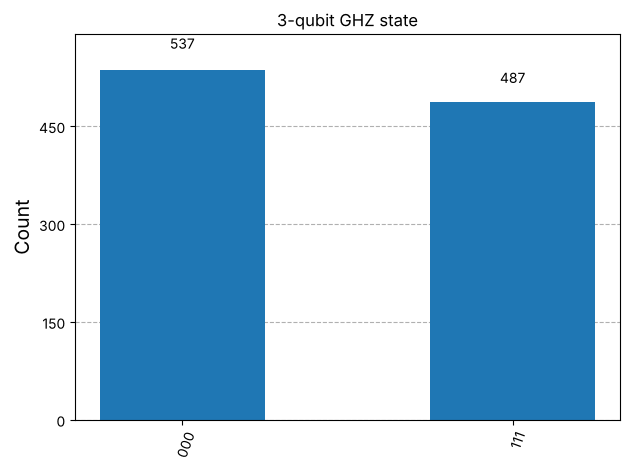

In [6]:
n = 3
ghz = QuantumCircuit(n)
ghz.h(0)
for q in range(n - 1):
    ghz.cx(q, q + 1)
ghz.measure_all()
display(ghz.draw("mpl"))

counts = run(ghz)
print(counts)
plot_histogram(counts, title=f"{n}-qubit GHZ state")

## 5. Quantum teleportation

Alice sends the state of qubit `q0` to Bob's qubit `q2` using a shared Bell pair and two classical bits.

1. Prepare a random state on `q0` (here, a rotation by angles θ, φ).
2. Create a Bell pair between `q1` (Alice) and `q2` (Bob).
3. Alice does a Bell measurement on `q0` and `q1`.
4. Bob applies X and/or Z depending on Alice's results.

To check it worked, we apply the *inverse* of the preparation to `q2`. If the teleportation succeeded, `q2` returns to $|0\rangle$, so the Bob bit is always 0.

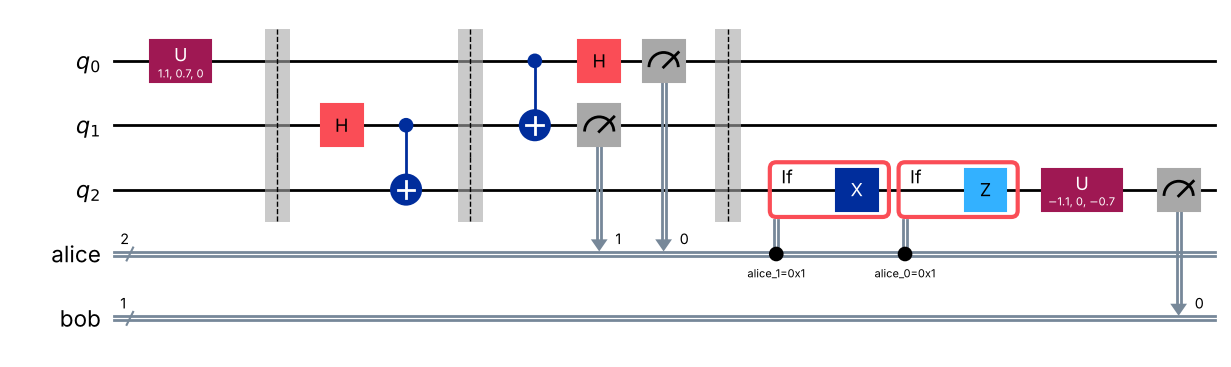

In [7]:
theta, phi = 1.1, 0.7   # try any angles you like

q = QuantumRegister(3, "q")
alice = ClassicalRegister(2, "alice")
bob = ClassicalRegister(1, "bob")
tp = QuantumCircuit(q, alice, bob)

# 1. State to teleport
tp.u(theta, phi, 0, q[0])
tp.barrier()

# 2. Bell pair between Alice (q1) and Bob (q2)
tp.h(q[1])
tp.cx(q[1], q[2])
tp.barrier()

# 3. Alice's Bell measurement
tp.cx(q[0], q[1])
tp.h(q[0])
tp.measure(q[0], alice[0])
tp.measure(q[1], alice[1])
tp.barrier()

# 4. Bob's corrections, conditioned on Alice's classical bits
with tp.if_test((alice[1], 1)):
    tp.x(q[2])
with tp.if_test((alice[0], 1)):
    tp.z(q[2])

# Undo the preparation on Bob's qubit and measure it
tp.u(-theta, 0, -phi, q[2])   # inverse of u(theta, phi, 0)
tp.measure(q[2], bob[0])

display(tp.draw("mpl"))

{'0 01': 266, '0 11': 258, '0 00': 242, '0 10': 258}
Bob measured 0 in 1024/1024 shots


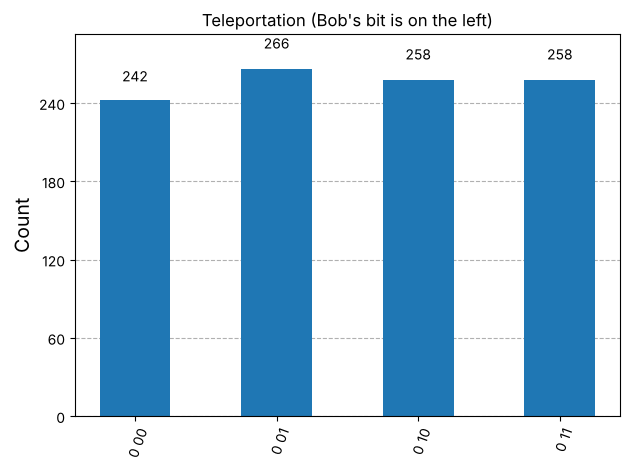

In [8]:
counts = run(tp)
print(counts)

# Count how often Bob's bit (the leftmost bit in each key) came out 0
bob_zero = sum(v for k, v in counts.items() if k.split()[0] == "0")
print(f"Bob measured 0 in {bob_zero}/{sum(counts.values())} shots")
plot_histogram(counts, title="Teleportation (Bob's bit is on the left)")

## 6. Grover's search algorithm (2 qubits)

Grover's algorithm finds a marked item in an unsorted list. With 4 items (2 qubits), one iteration finds the marked item with certainty.

- The **oracle** flips the sign of the marked state.
- The **diffuser** amplifies the marked state's amplitude.

Change `marked` to `"00"`, `"01"`, `"10"` or `"11"`.

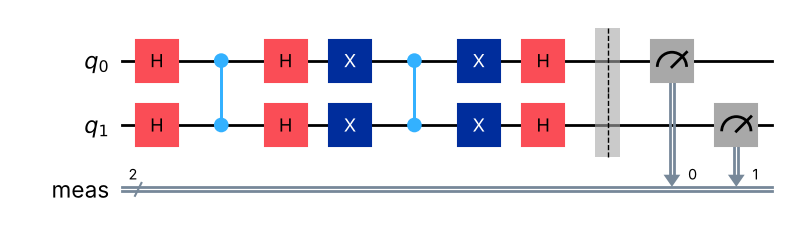

{'11': 1024}


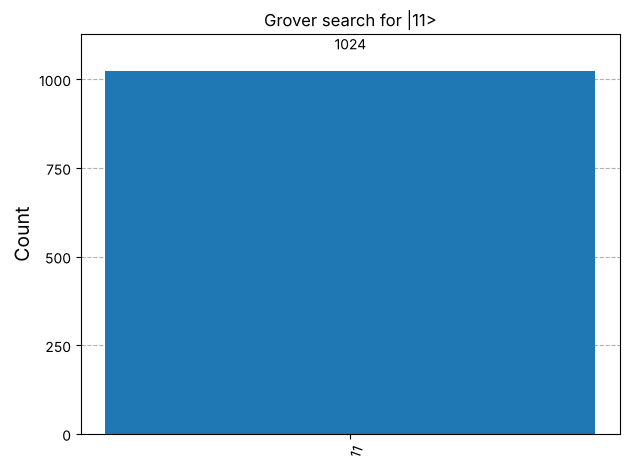

In [9]:
marked = "11"

def oracle(target):
    o = QuantumCircuit(2, name="Oracle")
    # Qiskit bit strings are written right-to-left (qubit 0 is the rightmost)
    zeros = [i for i, bit in enumerate(reversed(target)) if bit == "0"]
    if zeros:
        o.x(zeros)
    o.cz(0, 1)
    if zeros:
        o.x(zeros)
    return o

def diffuser():
    d = QuantumCircuit(2, name="Diffuser")
    d.h([0, 1])
    d.x([0, 1])
    d.cz(0, 1)
    d.x([0, 1])
    d.h([0, 1])
    return d

grover = QuantumCircuit(2)
grover.h([0, 1])
grover.compose(oracle(marked), inplace=True)
grover.compose(diffuser(), inplace=True)
grover.measure_all()
display(grover.draw("mpl"))

counts = run(grover)
print(counts)
plot_histogram(counts, title=f"Grover search for |{marked}>")

## 7. Deutsch–Jozsa algorithm

Given a function $f:\{0,1\}^n \to \{0,1\}$ that is promised to be either **constant** (same output for every input) or **balanced** (outputs 0 for exactly half the inputs), Deutsch–Jozsa tells which with a *single* query.

If the measured result is all zeros, the function is constant; otherwise it is balanced.

constant  oracle -> {'000': 100} -> algorithm says: constant


balanced  oracle -> {'010': 100} -> algorithm says: balanced


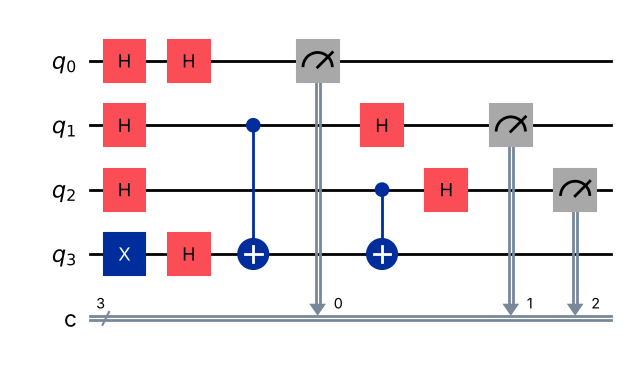

In [10]:
def dj_oracle(kind, n):
    o = QuantumCircuit(n + 1, name=f"{kind} oracle")
    if kind == "constant":
        if np.random.randint(2):
            o.x(n)              # f(x) = 1 for every x
    else:
        # Balanced: f(x) = parity of (x AND a random non-zero mask)
        mask = np.random.randint(1, 2**n)
        for i in range(n):
            if (mask >> i) & 1:
                o.cx(i, n)
    return o

def deutsch_jozsa(kind, n=3):
    qc = QuantumCircuit(n + 1, n)
    qc.x(n)
    qc.h(range(n + 1))
    qc.compose(dj_oracle(kind, n), inplace=True)
    qc.h(range(n))
    qc.measure(range(n), range(n))
    return qc

for kind in ["constant", "balanced"]:
    qc = deutsch_jozsa(kind)
    counts = run(qc, shots=100)
    verdict = "constant" if list(counts) == ["0" * 3] else "balanced"
    print(f"{kind:9} oracle -> {counts} -> algorithm says: {verdict}")

display(deutsch_jozsa("balanced").draw("mpl"))

## 8. (Optional) Run on real IBM quantum hardware

IBM offers free access to real quantum computers.

1. Create a free account at [quantum.cloud.ibm.com](https://quantum.cloud.ibm.com/) and copy your API key.
2. Uncomment the cell below, paste your key, and run it.

Jobs on real hardware wait in a queue, so this can take a few minutes. The results include some noise, so you'll see a few `01` and `10` counts in the Bell state that the simulator never produced.

In [11]:
# %pip install -q qiskit-ibm-runtime
# from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2
#
# service = QiskitRuntimeService(channel="ibm_quantum_platform", token="PASTE_YOUR_API_KEY_HERE")
# backend = service.least_busy(operational=True, simulator=False)
# print("Running on", backend.name)
#
# job = SamplerV2(backend).run([transpile(bell, backend)], shots=1024)
# counts = job.result()[0].data.meas.get_counts()
# plot_histogram(counts, title=f"Bell state on {backend.name}")

## Next steps

- Change the angles in the teleportation cell, or the `marked` state in Grover's search.
- Build your own circuit: `QuantumCircuit(n)` and gates like `h`, `x`, `y`, `z`, `s`, `t`, `rx`, `ry`, `rz`, `cx`, `cz`, `swap`, `ccx`.
- Learn more at [IBM Quantum Learning](https://quantum.cloud.ibm.com/learning).